# 02 - Extract Training Data (V2.0)

**What's different from V1:**
- Column names in your training polygon layer are matched with whitespace stripped, so a field literally named `"class_name "` (as in `mumbai_lulc.gpkg`) is found correctly.
- The actual class_id -> class_name mapping in your data is printed and cross-checked against `config_v2.CLASSES`, with any mismatch clearly flagged rather than silently assumed.
- Pixels that are NaN (nodata) in any of the 9 features are excluded during extraction, not left for a separate cleaning pass.

**Before running:** run `01_data_preparation_v2.ipynb` first.

**Output used by the next notebook:** `data/training/training_pixels.csv`

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path('..') / 'scripts'))

import config_v2 as config
import training_v2 as training


## Check inputs

In [2]:
if not config.FINAL_STACK_PATH.exists():
    raise FileNotFoundError(
        f'{config.FINAL_STACK_PATH} not found -- run 01_data_preparation_v2.ipynb first.'
    )
if not config.TRAINING_POLYGONS_PATH.exists():
    raise FileNotFoundError(
        f'{config.TRAINING_POLYGONS_PATH} not found -- '
        'set config_v2.TRAINING_POLYGONS_PATH to your polygon file.'
    )
print('Inputs found.')


Inputs found.


## Load polygons and see the ACTUAL classes in your data

This reads real values from your GeoPackage -- it does not trust `config.CLASSES` blindly.

In [3]:
polygons = training.load_training_polygons()
print(f'{len(polygons)} training polygons loaded from {config.TRAINING_POLYGONS_PATH.name}')
actual_classes = training.report_actual_classes(polygons)


28 training polygons loaded from training.gpkg
Classes found in training polygon data:
  class_id 1: 'water' (5 polygons)
  class_id 2: 'built_up' (6 polygons) | config.py says: 'Built-up'  <-- MISMATCH vs config.CLASSES
  class_id 3: 'vegetation' (7 polygons)
  class_id 4: 'agriculture' (6 polygons)
  class_id 5: 'barren' (4 polygons)


## Extract pixel values under each polygon

In [4]:
raw_training_df = training.extract_training_pixels()
raw_training_df.head()


Classes found in training polygon data:
  class_id 1: 'water' (5 polygons)
  class_id 2: 'built_up' (6 polygons) | config.py says: 'Built-up'  <-- MISMATCH vs config.CLASSES
  class_id 3: 'vegetation' (7 polygons)
  class_id 4: 'agriculture' (6 polygons)
  class_id 5: 'barren' (4 polygons)
class_id 1 (Water): 325231 valid pixels (0 excluded as nodata/outside raster)
class_id 2 (Built-up): 414532 valid pixels (0 excluded as nodata/outside raster)
class_id 3 (Vegetation): 768582 valid pixels (0 excluded as nodata/outside raster)
class_id 4 (Agriculture): 124483 valid pixels (0 excluded as nodata/outside raster)
class_id 5 (Barren): 223366 valid pixels (0 excluded as nodata/outside raster)


,B02,B03,B04,B08,B11,B12,NDVI,NDWI,NDBI,class
0,0.2557,0.2263,0.1998,0.1866,0.133106,0.116300,-0.034161,0.096149,-0.167322,1
1,0.2539,0.2251,0.1998,0.1850,0.133631,0.116475,-0.038462,0.097781,-0.161217,1
2,0.2527,0.2250,0.2008,0.1860,0.133194,0.116325,-0.038263,0.094890,-0.165436,1
3,0.2530,0.2259,0.1999,0.1865,0.133069,0.116144,-0.034679,0.095538,-0.167198,1
4,0.2551,0.2236,0.2006,0.1865,0.133256,0.115931,-0.036425,0.090466,-0.166514,1


## Clean the training data

In [5]:
training_df = training.clean_training_data(raw_training_df)
training_df['class'].value_counts()


Cleaned training data: 1856194 -> 1856194 rows (0 removed)


class
3    768582
2    414532
1    325231
5    223366
4    124483
Name: count, dtype: int64

## Save to CSV

In [6]:
training.save_training_csv(training_df)


Saved training data -> D:\2.0\project_v2\data\training\training_pixels.csv (1856194 rows)


'D:\\2.0\\project_v2\\data\\training\\training_pixels.csv'

## Quick look: feature distributions per class

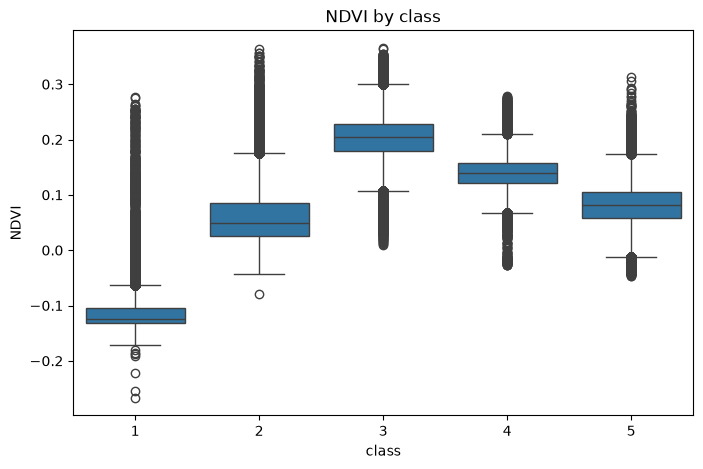

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=training_df, x='class', y='NDVI', ax=ax)
ax.set_title('NDVI by class')
plt.show()


## Done

**Next notebook:** `03_train_models_v2.ipynb`